# Predicting MOT failure of cars in Great Britain

**Module:** 6COSC017C Machine Learning and Data Analytics · **CW1** · Notebook

**Question.** Before a car's annual MOT test, can facts a buyer or owner already knows predict whether it will **fail**?
- Those facts are age, mileage, make and model, fuel, engine size, region and the previous test's result.
- Fail means `F` or `PRS`: the car arrived with failure-level defects.

| section | contents |
|---|---|
| A | Data sources and loading (joins) |
| B | Exploratory data analysis |
| C | Data preparation |
| D | Modelling |
| E | Evaluation |

Reproduce: `uv sync`, then run all cells. Every file this notebook reads is in the repository; how they were built from DVSA's open data is in `data/SOURCE.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from motfail.data import make_label
from motfail.load import load_fuel_lookup, load_history, load_outcome_lookup, load_sample

SEED = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")

## A. Data sources and loading

All data is published by the Driver and Vehicle Standards Agency (DVSA) as *Anonymised MOT tests and results*, under the Open Government Licence v3.0.

| source | file in this repo | key |
|---|---|---|
| 2025 test results (initial car tests, 1M sample) | `data/processed/mot_2025_sample.parquet` | `test_id`, `vehicle_id` |
| 2024 test results + 2024 test items (each car's previous test and its defects) | `data/processed/mot_2025_history.parquet` | `test_id` |
| DVSA lookup: fuel types | `data/lookup/dft_mdr_fuel_type_extract.csv` | `fuel_code` |
| DVSA lookup: test outcomes | `data/lookup/dft_mdr_test_outcome_extract.csv` | `result_code` |

### A.1 The 2025 sample

In [2]:
sample = load_sample()
print(f"{len(sample):,} rows × {sample.shape[1]} columns")
sample.sample(5, random_state=SEED)  # random rows: the source file is in mileage-sorted runs, so head() shows only zeros

1,000,000 rows × 14 columns


,test_id,vehicle_id,test_date,test_class_id,test_type,test_result,test_mileage,postcode_area,make,model,colour,fuel_type,cylinder_capacity,first_use_date
987231,1347023861,40492082,2025-12-15,4,NT,F,"57,854.000",CA,JAGUAR,XJ,BLUE,PE,"2,967.000",2004-03-31
79954,193861775,1303244295,2025-01-14,4,NT,P,"108,563.000",TF,FORD,TRANSIT,SILVER,DI,"2,198.000",2016-04-29
567130,1597582475,385043058,2025-07-04,4,NT,F,"130,798.000",IP,AUDI,A3,SILVER,PE,"1,595.000",2009-09-12
500891,620260615,1394232105,2025-06-09,4,NT,P,"29,868.000",SO,FORD,FIESTA TREND,GREY,PE,"1,084.000",2022-06-30
55399,196160821,1285318032,2025-01-21,4,NT,P,"75,056.000",RG,MAZDA,626,GREEN,PE,"1,991.000",2000-05-13


### A.2 Previous-test history

In [3]:
history = load_history()
print(f"{len(history):,} rows × {history.shape[1]} columns")
history.sample(5, random_state=SEED)

1,000,000 rows × 12 columns


,test_id,has_prev_test,prev_result,prev_fail,days_since_prev,miles_since_prev,mileage_rollback,prev_items_A,prev_items_F,prev_items_M,prev_items_P,prev_dangerous
987231,1347023861,0,NaN,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN
79954,193861775,1,P,0,365.000,"8,350.000",0,1.000,0.000,0.000,0.000,0.000
567130,1597582475,1,F,1,415.000,"6,564.000",0,4.000,2.000,2.000,0.000,1.000
500891,620260615,0,NaN,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN
55399,196160821,1,F,1,344.000,"9,216.000",0,0.000,1.000,0.000,0.000,0.000


### A.3 Join 1: sample ⨝ history on `test_id` (one-to-one)

In [4]:
assert sample["test_id"].is_unique, "duplicate test_id in sample"
assert history["test_id"].is_unique, "duplicate test_id in history"
assert sample["vehicle_id"].is_unique, "a vehicle appears twice"

df = sample.merge(history, on="test_id", how="left", validate="one_to_one", indicator=True)
print(f"sample {len(sample):,} | history {len(history):,} | joined {len(df):,}")
print(df["_merge"].value_counts().to_string())
df = df.drop(columns="_merge")

sample 1,000,000 | history 1,000,000 | joined 1,000,000
_merge
both          1000000
left_only           0
right_only          0


In [5]:
df["test_date"] = pd.to_datetime(df["test_date"])
df["first_use_date"] = pd.to_datetime(df["first_use_date"], errors="coerce")
df["vehicle_age_years"] = (df["test_date"] - df["first_use_date"]).dt.days / 365.25

no_prev = df["has_prev_test"] == 0
print(f"with a 2024 previous test: {(~no_prev).sum():,} ({(~no_prev).mean():.2%})")
print(f"without:                   {no_prev.sum():,} ({no_prev.mean():.2%})")
print("\nVehicle age (years) of tests without a previous test:")
print(df.loc[no_prev, "vehicle_age_years"].describe(percentiles=[.1, .25, .5, .75, .9]).to_string())
print(f"\nshare of them aged under 4 years: {(df.loc[no_prev, 'vehicle_age_years'] < 4).mean():.2%}")

with a 2024 previous test: 909,202 (90.92%)
without:                   90,798 (9.08%)

Vehicle age (years) of tests without a previous test:
count   90,798.000
mean         7.584
std          7.823
min         -0.003
10%          2.902
25%          2.960
50%          3.001
75%         10.951
90%         17.758
max        120.665

share of them aged under 4 years: 59.77%


**Join 1 result.** All 1,000,000 sample rows match exactly one history row (`validate="one_to_one"`, no `left_only` or `right_only` rows), so the join neither drops nor duplicates a test.

**Tests without a previous test: 90,798 (9.08%).** These are not failed matches: the history row exists, but the car had no initial test in 2024.
- **59.8%** of them are cars **under 4 years old** (median age 3.0). It is their first MOT, which is due at 3 years, so no earlier test exists.
- The rest are older cars whose previous test was before 2024, e.g. a car that was off the road for a while.

Their history features are missing *by design*. Section C keeps these rows and adds the `has_prev_test` flag, rather than dropping 9% of the data and every first-MOT car with them.

### A.4 Join 2: fuel codes ⨝ DVSA fuel lookup (many-to-one)

In [6]:
fuel = load_fuel_lookup()
assert fuel["fuel_code"].is_unique
print("raw fuel_type values in the sample:")
print(df["fuel_type"].value_counts(dropna=False).to_string())

raw fuel_type values in the sample:
fuel_type
PE                         532444
DI                         393170
HY                          40465
EL                          18857
HYBRID ELECTRIC (CLEAN)     10048
ED                           2650
ELECTRIC                     1777
GB                            224
OT                            184
LP                            168
CN                              4
FC                              4
GA                              4
GD                              1


In [7]:
before = len(df)
df = df.merge(fuel, left_on="fuel_type", right_on="fuel_code", how="left", validate="many_to_one")
assert len(df) == before
unmatched = df["fuel_name"].isna()
print(f"matched {(~unmatched).sum():,} | unmatched {unmatched.sum():,}")
print(df.loc[unmatched, "fuel_type"].value_counts(dropna=False).to_string())

matched 988,175 | unmatched 11,825
fuel_type
HYBRID ELECTRIC (CLEAN)    10048
ELECTRIC                    1777


**Join 2 result.** 988,175 rows (98.8%) match a DVSA fuel code. The 11,825 unmatched rows are not unknown fuels: the raw field sometimes holds the full name instead of the code.
- `HYBRID ELECTRIC (CLEAN)` (10,048 rows) is the lookup's name for `HY`.
- `ELECTRIC` (1,777 rows) is the lookup's name for `EL`.

Section C maps them back to their codes (error correction). The lookup also settles `ED`: it is *Electric Diesel*, a diesel hybrid.

### A.5 Join 3: outcomes ⨝ DVSA outcome lookup, and the target

In [8]:
outcome = load_outcome_lookup()
before = len(df)
df = df.merge(outcome, left_on="test_result", right_on="result_code", how="left", validate="many_to_one")
assert len(df) == before and df["result_name"].notna().all()
df["fail"] = make_label(df)
df.groupby(["test_result", "result_name"], observed=True).size().rename("tests").to_frame()

,,tests
test_result,result_name,
F,Failed,227881
P,Passed,719072
PRS,Pass with Rectification at Station,53047


**The target.**
- `fail = 1` for **F** (*Failed*) and **PRS** (*Pass with Rectification at Station*).
- `fail = 0` for **P** (*Passed*).

A PRS car *arrived* with failure-level defects that were repaired during the test. The buyer's question is about the car's state on arrival, so PRS counts as a fail. A sensitivity check with PRS counted as a pass is planned for Section E.

Retests and abandoned or aborted tests were excluded when the sample was built (`data/SOURCE.md`).

## B. Exploratory data analysis

### B.1 Structure and types

In [9]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 31 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   test_id            1000000 non-null  int64         
 1   vehicle_id         1000000 non-null  int64         
 2   test_date          1000000 non-null  datetime64[us]
 3   test_class_id      1000000 non-null  int64         
 4   test_type          1000000 non-null  category      
 5   test_result        1000000 non-null  str           
 6   test_mileage       1000000 non-null  float64       
 7   postcode_area      1000000 non-null  category      
 8   make               1000000 non-null  category      
 9   model              999999 non-null   category      
 10  colour             1000000 non-null  category      
 11  fuel_type          1000000 non-null  str           
 12  cylinder_capacity  979271 non-null   float64       
 13  first_use_date     1000000 non-null  da

31 columns, 194 MB in memory.
- Text fields with few distinct values are stored as `category` to save memory.
- The dates are real datetimes. `test_date` is only used to derive features (vehicle age, month), never as a raw model input.
- `test_id` and `vehicle_id` are identifiers, used for joins and the split, never as features.

### B.2 Numeric summary: centre, spread, shape

In [10]:
df["test_month"] = df["test_date"].dt.month
numeric = [
    "vehicle_age_years", "test_mileage", "cylinder_capacity",
    "days_since_prev", "miles_since_prev",
    "prev_items_F", "prev_items_P", "prev_items_A", "prev_items_M", "prev_dangerous",
]
summary = df[numeric].describe(percentiles=[.01, .25, .5, .75, .99]).T
summary["var"] = df[numeric].var()
summary["skew"] = df[numeric].skew()
summary["kurtosis"] = df[numeric].kurt()
summary["missing_%"] = df[numeric].isna().mean() * 100
summary

,count,mean,std,min,1%,25%,50%,75%,99%,max,var,skew,kurtosis,missing_%
vehicle_age_years,"1,000,000.000",10.701,5.621,-0.003,2.902,6.749,9.930,13.900,27.135,120.665,31.593,1.552,7.495,0.000
test_mileage,"1,000,000.000","75,275.823","45,753.231",0.000,"7,821.000","41,111.000","67,480.000","100,552.000","212,264.020","999,999.000","2,093,358,178.931",1.344,6.032,0.000
cylinder_capacity,"979,271.000","1,690.752",597.665,0.000,989.000,"1,329.000","1,590.000","1,991.000","3,950.000","55,000.000","357,203.796",3.841,142.528,2.073
days_since_prev,"909,202.000",363.011,39.127,2.000,183.000,357.000,364.000,371.000,480.000,727.000,"1,530.923",-1.691,20.746,9.080
miles_since_prev,"909,202.000","6,698.408","8,747.466","-873,599.000",59.000,"3,086.000","5,654.000","9,054.000","26,112.000","986,317.000","76,518,159.838",2.844,"1,722.146",9.080
prev_items_F,"909,202.000",0.498,1.256,0.000,0.000,0.000,0.000,0.000,6.000,33.000,1.579,3.626,18.192,9.080
prev_items_P,"909,202.000",0.080,0.363,0.000,0.000,0.000,0.000,0.000,2.000,13.000,0.132,5.794,44.647,9.080
prev_items_A,"909,202.000",1.302,1.860,0.000,0.000,0.000,0.000,2.000,8.000,36.000,3.461,2.149,7.350,9.080
prev_items_M,"909,202.000",0.144,0.459,0.000,0.000,0.000,0.000,0.000,2.000,10.000,0.211,4.094,22.224,9.080
prev_dangerous,"909,202.000",0.099,0.403,0.000,0.000,0.000,0.000,0.000,2.000,10.000,0.163,5.190,34.599,9.080


**Reading the table.**
- **Vehicle age:** median 9.9 years, mean 10.7, right-skewed (skew 1.55). Most cars are 7–14 years old, with a long tail of classics (maximum 120.7 years). The minimum, −0.003, is impossible: a first-use date after the test date.
- **Mileage:** median 67,480, mean 75,276 miles; skew 1.34. The maximum, 999,999, is a placeholder, not a reading.
- **Engine size:** median 1,590 cc. Kurtosis 142.5 means extreme outliers, up to 55,000 cc, which is not a real car engine.
- **Days since the previous test:** tightly centred on one year (median 364, middle half 357–371), the annual MOT cycle, with a short left tail (minimum 2 days).
- **Miles since the previous test:** median 5,654 a year. Kurtosis 1,722 comes from a few impossible jumps (−873,599 to +986,317), i.e. odometer errors.
- **Item counts at the previous test:** zero-inflated and right-skewed (all medians 0). Most cars had no failure items; a few had many (maximum 33).

**Why it matters for modelling.** Skew and outliers distort distance-based and linear models (KNN, logistic regression) far more than trees. Section C caps the impossible values and scales features for the models that need it.

### B.3 Missing values and impossible values

In [11]:
miss = pd.DataFrame({"missing": df.isna().sum(), "missing_%": df.isna().mean() * 100})
miss[miss["missing"] > 0].sort_values("missing", ascending=False)

,missing,missing_%
prev_fail,90798,9.080
prev_result,90798,9.080
days_since_prev,90798,9.080
miles_since_prev,90798,9.080
prev_items_A,90798,9.080
mileage_rollback,90798,9.080
prev_items_P,90798,9.080
prev_dangerous,90798,9.080
prev_items_F,90798,9.080
prev_items_M,90798,9.080


In [12]:
checks = {
    "test_mileage == 0": (df["test_mileage"] == 0).sum(),
    "test_mileage > 500,000": (df["test_mileage"] > 500_000).sum(),
    "cylinder_capacity == 0": (df["cylinder_capacity"] == 0).sum(),
    "cylinder_capacity > 8,000": (df["cylinder_capacity"] > 8_000).sum(),
    "first_use_date after test_date": (df["first_use_date"] > df["test_date"]).sum(),
    "vehicle age < 2.5 years": (df["vehicle_age_years"] < 2.5).sum(),
    "model == 'UNCLASSIFIED'": (df["model"] == "UNCLASSIFIED").sum(),
    "make == 'UNCLASSIFIED'": (df["make"] == "UNCLASSIFIED").sum(),
    "mileage went down since previous test": (df["mileage_rollback"] == 1).sum(),
    "|miles since previous| > 100,000": (df["miles_since_prev"].abs() > 100_000).sum(),
    "previous test < 30 days before": (df["days_since_prev"] < 30).sum(),
}
pd.Series(checks, name="rows").to_frame()

,rows
test_mileage == 0,1786
"test_mileage > 500,000",79
cylinder_capacity == 0,30
"cylinder_capacity > 8,000",34
first_use_date after test_date,1
vehicle age < 2.5 years,2457
model == 'UNCLASSIFIED',2065
make == 'UNCLASSIFIED',2
mileage went down since previous test,2684
"|miles since previous| > 100,000",939


In [13]:
# Are these values errors, or do they carry information?
zero = df["test_mileage"] == 0
print(f"fail rate, mileage recorded as 0: {df.loc[zero, 'fail'].mean():.2%}  (n = {zero.sum():,})")
print(f"fail rate, mileage > 0:           {df.loc[~zero, 'fail'].mean():.2%}")
print("\nmissing engine size by fuel code:")
print(pd.crosstab(df["fuel_type"], df["cylinder_capacity"].isna().rename("cc missing"))
        .query("`True` > 0").to_string())
print(f"\ncars older than 40 years: {(df['vehicle_age_years'] > 40).sum():,}; "
      f"oldest first use: {df['first_use_date'].min().date()}")

fail rate, mileage recorded as 0: 48.82%  (n = 1,786)
fail rate, mileage > 0:           28.06%

missing engine size by fuel code:
cc missing                False  True 
fuel_type                             
DI                       393031    139
EL                          173  18684
ELECTRIC                     15   1762
FC                            2      2
HYBRID ELECTRIC (CLEAN)   10012     36
LP                          166      2
OT                          183      1
PE                       532341    103

cars older than 40 years: 1,501; oldest first use: 1904-12-30


**Three different reasons for missing values.**
1. **History features (9.08%):** no previous test, mostly first-MOT cars (A.3). This is not random, so the absence is information: keep a `has_prev_test` flag and impute.
2. **Engine size (2.07%):** 20,446 of the 20,729 gaps are electric cars (`EL`, `ELECTRIC`), which have no cylinders. Structurally missing, not an error.
3. **Fuel name (1.18%):** the word-coded fuels from A.4, fixable exactly.

**Suspicious values** (counts in the table above):
- 1,786 zero mileages and 79 above 500,000 miles
- 30 zero and 34 above-8,000 cc engines
- 1 car first used after its test
- 2,065 `UNCLASSIFIED` models
- 939 impossible mileage changes between tests
- 374 tests less than 30 days after the previous one: in effect retests across the new year (`data/SOURCE.md`)

**Error or information?** Cars with mileage recorded as **0** fail **48.8%** of the time, against **28.1%** for the rest. So a zero is not a harmless gap; it probably marks an unreadable or broken odometer. Section C turns it into a flag instead of silently replacing it, so the model keeps the signal.

1,501 cars are **over 40 years old** (the oldest first used in 1904). Most cars over 40 are exempt from the MOT, so these are mostly voluntary tests of classics: a small, unusual group, not errors.

### B.4 Categorical features

In [14]:
categorical = ["make", "model", "colour", "postcode_area", "fuel_type"]
pd.DataFrame({
    "unique": [df[c].nunique() for c in categorical],
    "top": [df[c].value_counts().index[0] for c in categorical],
    "top_share_%": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in categorical],
    "values covering 90% of rows": [
        int((df[c].value_counts(normalize=True).cumsum() < 0.9).sum() + 1) for c in categorical
    ],
}, index=categorical)

,unique,top,top_share_%,values covering 90% of rows
make,779,FORD,13.263,21
model,8426,FIESTA,3.887,604
colour,20,BLACK,19.137,6
postcode_area,119,B,3.088,89
fuel_type,14,PE,53.244,2


**High cardinality.**
- 779 makes, but 21 cover 90% of tests.
- **8,426 models**, of which 604 are needed to cover 90%.
- 119 postcode areas.

One-hot encoding of `model` would create thousands of sparse columns. Section C groups rare values and uses frequency or target encoding fitted inside cross-validation.

`fuel_type` is dominated by two values: petrol 53.2%, then diesel.

### B.5 Target balance

              tests  share_%
test_result                 
P            719072   71.907
F            227881   22.788
PRS           53047    5.305

fail (F + PRS): 280,928 of 1,000,000 = 28.09%
majority-class baseline accuracy (always 'pass'): 71.91%


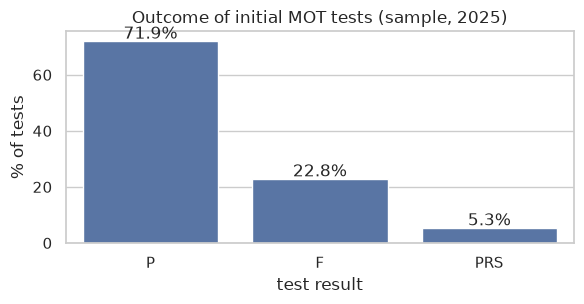

In [15]:
balance = df["test_result"].value_counts().rename("tests").to_frame()
balance["share_%"] = balance["tests"] / len(df) * 100
print(balance.to_string())
print(f"\nfail (F + PRS): {df['fail'].sum():,} of {len(df):,} = {df['fail'].mean():.2%}")
print(f"majority-class baseline accuracy (always 'pass'): {1 - df['fail'].mean():.2%}")

fig, ax = plt.subplots(figsize=(6, 3.2))
order = ["P", "F", "PRS"]
sns.barplot(x=order, y=[balance.loc[o, "share_%"] for o in order], ax=ax, color="#4c72b0")
ax.set(xlabel="test result", ylabel="% of tests", title="Outcome of initial MOT tests (sample, 2025)")
for i, o in enumerate(order):
    ax.text(i, balance.loc[o, "share_%"] + 1, f"{balance.loc[o, 'share_%']:.1f}%", ha="center")
plt.tight_layout(); plt.show()

**An imbalanced target.**
- 71.9% pass, 22.8% fail and 5.3% PRS, so **28.09% are fails**.
- A model that always predicts *pass* would score **71.9% accuracy** while catching no failing car. Accuracy is therefore not our main metric.

Section D uses precision, recall, F1 and PR-AUC; its random baseline is 0.281, the positive rate. It also stratifies every split, so each part keeps the 28% fail share.

### B.6 Fail rate by month

             tests  fail_rate
test_month                   
1            92680      0.287
2            84861      0.281
3           101471      0.272
4            74908      0.278
5            75489      0.272
6            80697      0.271
7            84066      0.283
8            78212      0.281
9            96967      0.276
10           94938      0.293
11           79262      0.292
12           56449      0.287


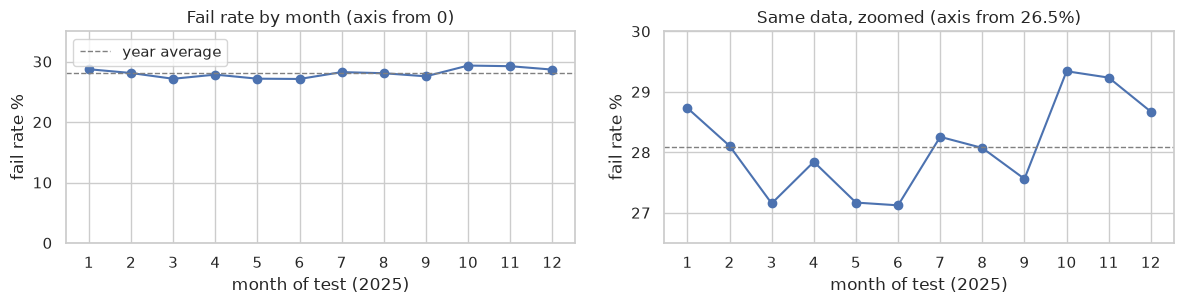

In [16]:
by_month = df.groupby("test_month")["fail"].agg(tests="size", fail_rate="mean")
print(by_month.to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, (ylim, title) in zip(axes, [((0, 35), "Fail rate by month (axis from 0)"),
                                    ((26.5, 30), "Same data, zoomed (axis from 26.5%)")]):
    ax.plot(by_month.index, by_month["fail_rate"] * 100, marker="o")
    ax.axhline(df["fail"].mean() * 100, ls="--", c="grey", lw=1, label="year average")
    ax.set(xlabel="month of test (2025)", ylabel="fail rate %", title=title, xticks=range(1, 13), ylim=ylim)
axes[0].legend(); plt.tight_layout(); plt.show()

**Seasonality is small but real.** The monthly fail rate moves between 27.1% (June) and 29.3% (October), a range of 2.2 percentage points. The left panel shows how small that is against the overall rate.
- **Higher from October to January.** Plausible but untested: winter wear on tyres, lights and wipers.
- **Part of the October–December rise is caused by how the sample was built** (one test per car, the earliest). Late in the year, cars that already had a 2025 test are excluded, and repeat tests mostly pass. Across *all* tests the October–December rates are 28.6%, 28.3% and 27.6% (`data/SOURCE.md`).

So `test_month` goes in as a feature, and the effect is described as *associated with* season, not caused by it.

### B.7 Distributions of the main numeric features, split by outcome

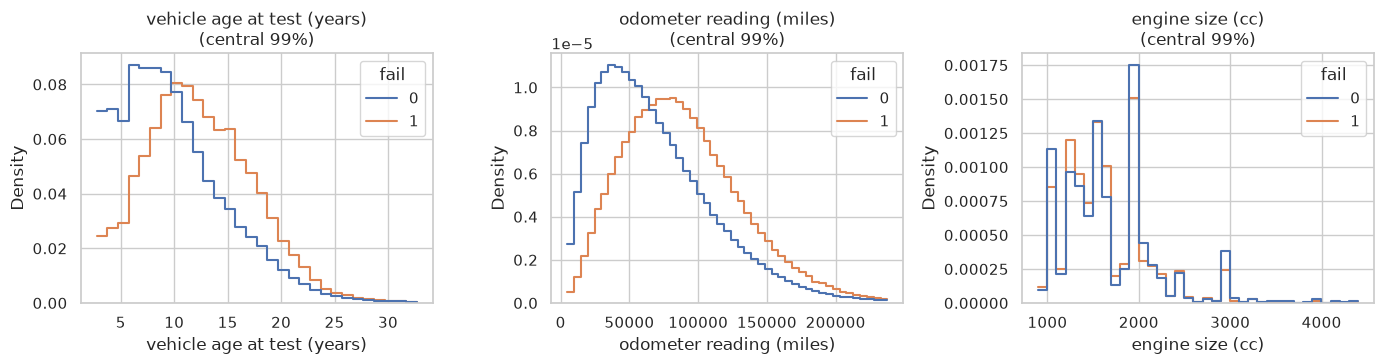

In [17]:
plot_cols = {
    "vehicle_age_years": "vehicle age at test (years)",
    "test_mileage": "odometer reading (miles)",
    "cylinder_capacity": "engine size (cc)",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (col, label) in zip(axes, plot_cols.items()):
    lo, hi = df[col].quantile([0.005, 0.995])
    data = df[df[col].between(lo, hi)]
    binwidth = {"vehicle_age_years": 1, "test_mileage": 5_000, "cylinder_capacity": 100}[col]
    sns.histplot(data=data, x=col, hue="fail", stat="density", common_norm=False,
                 binwidth=binwidth, element="step", fill=False, ax=ax)
    ax.set(xlabel=label, title=f"{label}\n(central 99%)")
plt.tight_layout(); plt.show()

**What the distributions show.**
- **Age and mileage separate the classes.** The fail curves (1) sit clearly to the right: failing cars are older and have done more miles. These will be strong features, but they are correlated with each other (old cars have more miles). Section B.8 measures that.
- **Engine size barely separates them.** The spikes are standard engine sizes (1.0, 1.2, 1.4, 1.6 and 2.0 litres), not noise, and both classes share them.
- Age and mileage are right-skewed, so they are candidates for a log transform for the linear model (Section C).

### B.8 Correlation and association

The measure depends on the variable types (lecture 2, p.32):

| pair | measure | why |
|---|---|---|
| numeric × numeric | **Pearson** (linear) and **Spearman** (rank, monotonic) | both are shown because most features are skewed with outliers (B.2), which distorts Pearson |
| numeric × binary target | **point-biserial**, i.e. Pearson against `fail` (0/1) | |
| categorical × categorical (including the target) | **Cramér's V** (0–1) | |

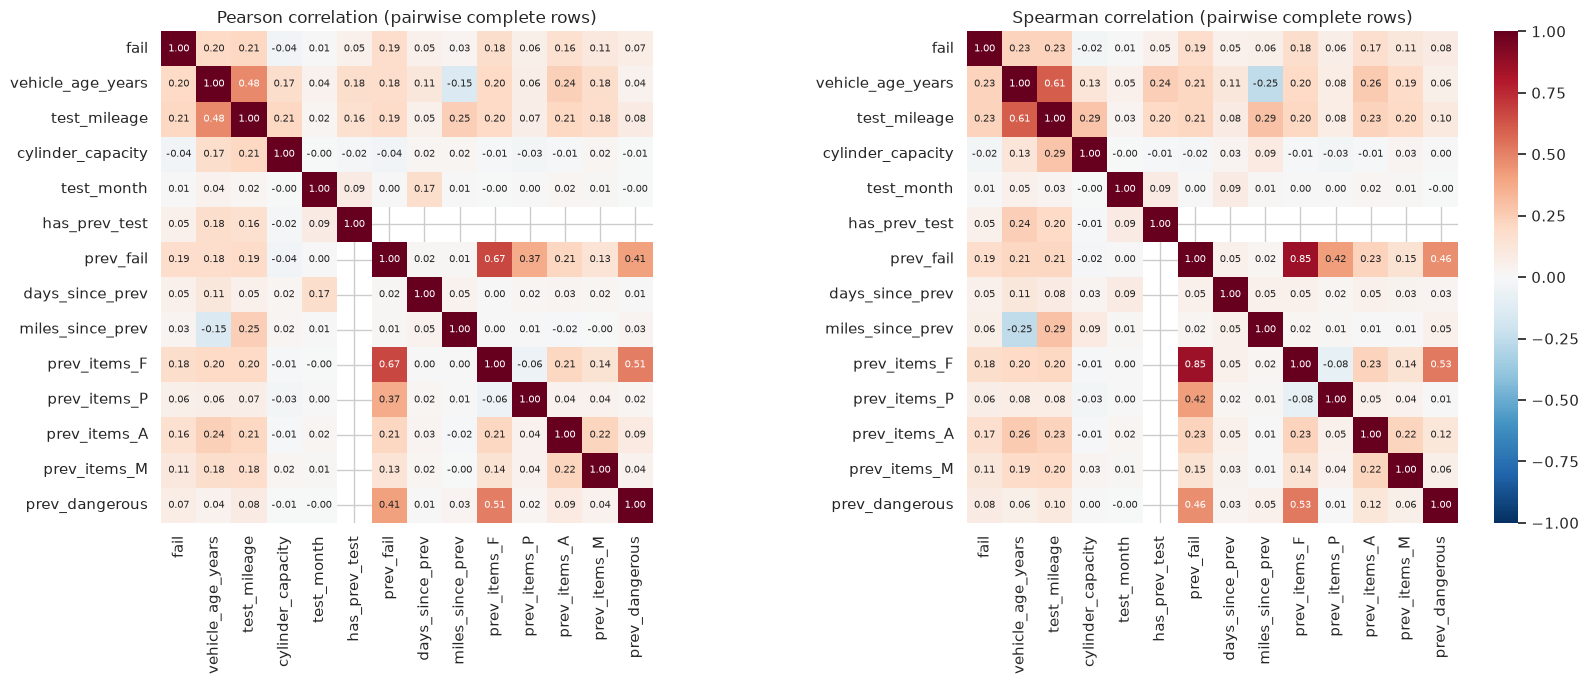

In [18]:
corr_cols = [
    "fail", "vehicle_age_years", "test_mileage", "cylinder_capacity", "test_month",
    "has_prev_test", "prev_fail", "days_since_prev", "miles_since_prev",
    "prev_items_F", "prev_items_P", "prev_items_A", "prev_items_M", "prev_dangerous",
]
num = df[corr_cols].astype("float64")
pearson = num.corr(method="pearson")
spearman = num.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, (name, m) in zip(axes, [("Pearson", pearson), ("Spearman", spearman)]):
    sns.heatmap(m, ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
                annot_kws={"size": 7}, cbar=ax is axes[1], square=True)
    ax.set_title(f"{name} correlation (pairwise complete rows)")
plt.tight_layout(); plt.show()

**Reading the heatmaps.**
- **Age and mileage are strongly related:** Spearman 0.61, Pearson 0.48. Spearman is higher because the relation is monotonic but not linear, and the outliers from B.2 drag Pearson down. For logistic regression this collinearity makes individual coefficients unstable, so they are interpreted with care.
- **The history features are partly redundant.** `prev_fail` and `prev_items_F` have Spearman 0.85: a previous fail almost always means at least one F item. Section C checks whether both are worth keeping.
- **Weak pairs:**
  - `miles_since_prev` vs age: −0.25. Older cars are driven less per year.
  - `test_month`: near zero with everything.
- The **`has_prev_test` row is blank** beyond its own cell, by construction. The history features exist only when `has_prev_test = 1`, so on the rows where both are present it is constant and its correlation is undefined.

In [19]:
with_target = pd.DataFrame({
    "point-biserial (Pearson)": pearson["fail"].drop("fail"),
    "Spearman": spearman["fail"].drop("fail"),
}).sort_values("Spearman", key=abs, ascending=False)
with_target

,point-biserial (Pearson),Spearman
vehicle_age_years,0.197,0.232
test_mileage,0.206,0.229
prev_fail,0.186,0.186
prev_items_F,0.178,0.179
prev_items_A,0.161,0.167
prev_items_M,0.108,0.113
prev_dangerous,0.075,0.082
prev_items_P,0.061,0.063
miles_since_prev,0.029,0.059
has_prev_test,0.050,0.050


**Correlation with the target.**
- **No single feature is strong.** The largest is about 0.23 (age and mileage, Spearman), then `prev_fail` at 0.19 and the previous failure-item count at 0.18. Failure depends on many weak signals together, so a multivariable model is needed, and a perfect classifier should not be expected.
- **Spearman is higher than Pearson for age, mileage and `miles_since_prev`.** Their relation with failure is monotonic but not linear, and outliers weaken Pearson. Section C therefore considers transforms or bins for the linear model; trees do not need them.
- **Close to zero:**
  - `cylinder_capacity` (−0.02 to −0.04) and `test_month` (0.007). They are kept, but are not expected to matter much on their own.
  - Seasonality (B.6) is real but small.

In [20]:
from motfail.stats import cramers_v

df["prev_result_or_none"] = df["prev_result"].astype("string").fillna("none")
categorical_assoc = ["make", "model", "fuel_type", "colour", "postcode_area", "prev_result_or_none"]
cv = pd.DataFrame({
    "categories": [df[c].nunique() for c in categorical_assoc],
    "Cramér's V": [cramers_v(df[c], df["fail"]) for c in categorical_assoc],
    "Cramér's V (bias-corrected)": [cramers_v(df[c], df["fail"], bias_corrected=True) for c in categorical_assoc],
}, index=categorical_assoc).sort_values("Cramér's V (bias-corrected)", ascending=False)
cv

,categories,Cramér's V,Cramér's V (bias-corrected)
model,8426,0.228,0.209
prev_result_or_none,4,0.187,0.187
make,779,0.123,0.120
fuel_type,14,0.093,0.093
postcode_area,119,0.079,0.079
colour,20,0.049,0.049


**Categorical features vs fail (Cramér's V).**
- **`model` is the strongest (0.21 corrected)**, but it has 8,426 categories. The plain V (0.23) is slightly inflated by sparse cells, which is why the bias-corrected value (Bergsma, 2013; beyond the slides) is shown. Its signal is real but spread thinly, which is an overfitting risk. Section C encodes it with smoothing or frequency, fitted inside cross-validation.
- **The previous result comes next (0.19)**, then `make` (0.12), `fuel_type` (0.09) and `postcode_area` (0.08).
- **`colour` is weakest (0.05).** Section C tests whether it adds anything beyond age and model.

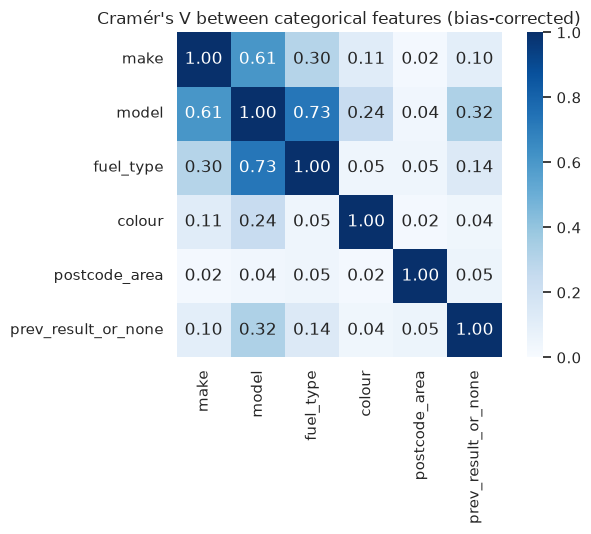

In [21]:
pairs = pd.DataFrame(index=categorical_assoc, columns=categorical_assoc, dtype=float)
for i, a in enumerate(categorical_assoc):
    for b in categorical_assoc[i:]:
        v = 1.0 if a == b else cramers_v(df[a], df[b], bias_corrected=True)
        pairs.loc[a, b] = pairs.loc[b, a] = v
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(pairs, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, ax=ax)
ax.set_title("Cramér's V between categorical features (bias-corrected)")
plt.tight_layout(); plt.show()

**Between categorical features.**
- `model` is nested inside `make` (V = 0.61; not 1, because some model names such as `UNCLASSIFIED` occur under many makes).
- `model` largely determines `fuel_type` (0.73).
- `model` also carries some of the previous-result signal (0.32): some models fail more year after year.
- `postcode_area` is nearly independent of the vehicle features (V ≤ 0.05), so region adds information of its own.

### B.9 Age, fuel and mileage

**Purpose:** age and mileage are the two strongest numeric signals (B.8), and they are correlated with each other. These plots ask two questions:
- Does each still matter when the other is held roughly fixed?
- Does the age effect differ by fuel?

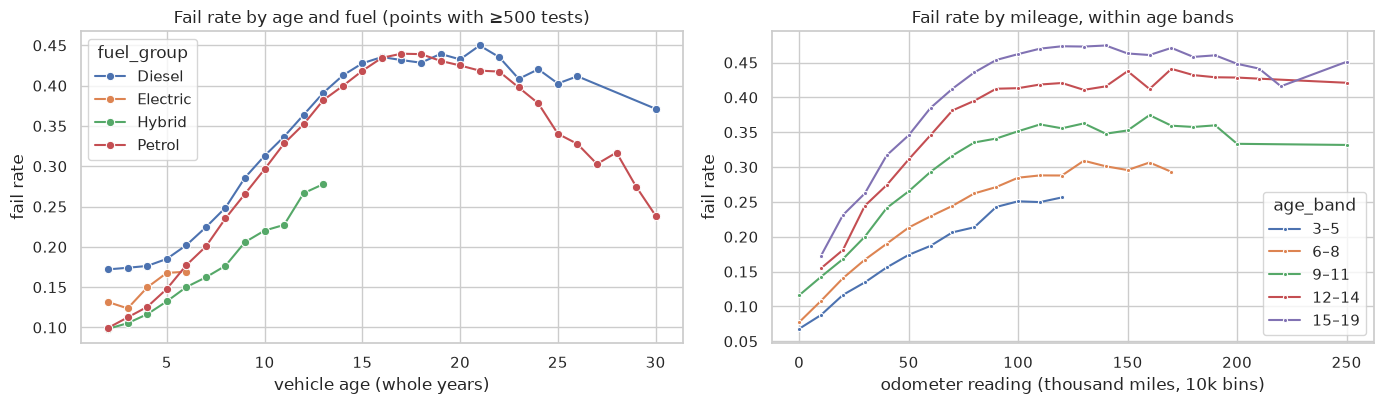

             tests  fail_rate
fuel_group                   
Petrol      532444      0.279
Diesel      393170      0.310
Hybrid       53163      0.141
Electric     20634      0.151
Other          589      0.241

fail rate by fuel at young ages (whole years):
fuel_group  Petrol  Diesel  Hybrid  Electric
age_year                                    
2.000        0.099   0.172   0.098     0.131
3.000        0.112   0.174   0.105     0.124
4.000        0.126   0.176   0.116     0.150
5.000        0.148   0.185   0.132     0.168
6.000        0.177   0.202   0.150     0.169


In [22]:
from motfail.app_data import AGE_BINS, AGE_LABELS
from motfail.clean import fuel_name_to_code
from motfail.features import FUEL_GROUPS

# some rows hold the fuel's name, not its code (A.4): map names to codes first, then group
fuel_code = df["fuel_type"].astype("string").replace(fuel_name_to_code())
df["fuel_group"] = fuel_code.map(FUEL_GROUPS).fillna("Other")
df["age_band"] = pd.cut(df["vehicle_age_years"], bins=AGE_BINS, labels=AGE_LABELS, right=False)
df["age_year"] = np.floor(df["vehicle_age_years"]).clip(upper=30)

MIN_N = 500  # rates from fewer tests are too noisy to plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

g = df.groupby(["fuel_group", "age_year"])["fail"].agg(["mean", "size"]).reset_index()
g = g[(g["size"] >= MIN_N) & (g["fuel_group"] != "Other")]
sns.lineplot(data=g, x="age_year", y="mean", hue="fuel_group", marker="o", ax=axes[0])
axes[0].set(xlabel="vehicle age (whole years)", ylabel="fail rate",
            title=f"Fail rate by age and fuel (points with ≥{MIN_N} tests)")

df["mileage_10k"] = (df["test_mileage"] // 10_000 * 10).clip(upper=250)
bands = ["3–5", "6–8", "9–11", "12–14", "15–19"]
m = df[df["age_band"].isin(bands) & (df["test_mileage"] > 0)]
m = m.groupby(["age_band", "mileage_10k"], observed=True)["fail"].agg(["mean", "size"]).reset_index()
m = m[m["size"] >= MIN_N]
sns.lineplot(data=m, x="mileage_10k", y="mean", hue="age_band", hue_order=bands, marker=".", ax=axes[1])
axes[1].set(xlabel="odometer reading (thousand miles, 10k bins)", ylabel="fail rate",
            title="Fail rate by mileage, within age bands")
plt.tight_layout(); plt.show()
print(df.groupby("fuel_group")["fail"].agg(tests="size", fail_rate="mean").sort_values("tests", ascending=False).to_string())
print("\nfail rate by fuel at young ages (whole years):")
print(df[df["age_year"].between(2, 6)].pivot_table(index="age_year", columns="fuel_group", values="fail",
      aggfunc="mean")[["Petrol", "Diesel", "Hybrid", "Electric"]].round(3).to_string())

**Insights.**
- **Age (left).**
  - The fail rate rises steeply from about 10–17% at 3 years to about 43% at 16–20 years.
  - For petrol cars it then **falls** (24% at 30 years). Very old cars still on the road are often well-kept classics, a *survivor effect*. So the relation is not monotonic at the top end, which matters for linear models.
  - **Young diesels fail more** than young petrol cars (17% vs 11% at 3 years); the two converge after about 15 years. Diesels are bought for high mileage, so part of this gap is mileage.
  - Hybrids fail less at almost every age (14.1% overall).
  - **Electric cars fail slightly more than petrol cars of the same age** at 2–5 years (e.g. 15.0% vs 12.6% at 4 years), and equally at 6. They are only up to 6 years old in this data, so their long-term pattern is unknown. A possible but untested reason is their extra weight, which wears tyres and suspension faster.
- **Mileage (right).** Within *every* age band the fail rate still rises with mileage, up to about 100,000 miles, and then flattens. So mileage carries information that age does not (and vice versa), and the effect is **non-linear with a plateau**: easy for trees, while the linear model needs bins or a transform.

### B.10 Make: raw fail rate vs age-adjusted (confounding)

**Purpose:** a raw fail rate by make mixes the make with the age of its cars on the road. To separate them, each make's fails are compared with the number *expected* if its cars failed at the overall rate for their age band (indirect standardisation).
- **Ratio above 1:** the make fails more than its age mix predicts.
- **Ratio below 1:** it fails less.

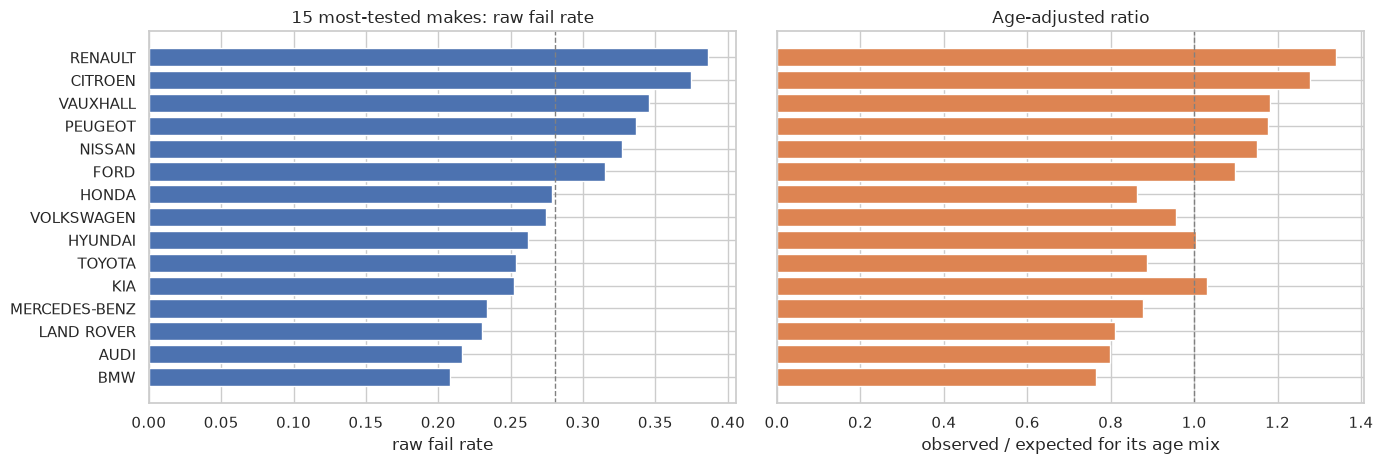

,tests,median_age,fail_rate,expected_rate,age_adjusted_ratio
make,,,,,
FORD,132633,10.075,0.315,0.287,1.097
VOLKSWAGEN,93655,10.193,0.274,0.287,0.956
VAUXHALL,85575,10.412,0.345,0.292,1.181
BMW,56480,9.292,0.208,0.273,0.764
AUDI,53070,9.314,0.216,0.271,0.797
TOYOTA,52364,10.218,0.254,0.286,0.887
MERCEDES-BENZ,51734,8.947,0.234,0.267,0.876
NISSAN,50631,9.988,0.327,0.284,1.151
PEUGEOT,42231,10.138,0.337,0.286,1.178


In [23]:
band_rate = df.groupby("age_band", observed=True)["fail"].mean()
df["expected_fail"] = df["age_band"].map(band_rate).astype("float64")

def age_adjusted(frame, by, top=None, min_n=MIN_N):
    t = frame.groupby(by, observed=True).agg(
        tests=("fail", "size"), fail_rate=("fail", "mean"),
        expected_rate=("expected_fail", "mean"), median_age=("vehicle_age_years", "median"))
    t["age_adjusted_ratio"] = t["fail_rate"] / t["expected_rate"]
    t = t[t["tests"] >= min_n]
    return t.sort_values("tests", ascending=False).head(top) if top else t

makes = age_adjusted(df, "make", top=15)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
order = makes.sort_values("fail_rate").index.astype(str)
axes[0].barh(order, makes.loc[order, "fail_rate"], color="#4c72b0")
axes[0].axvline(df["fail"].mean(), ls="--", c="grey", lw=1)
axes[0].set(xlabel="raw fail rate", title="15 most-tested makes: raw fail rate")
axes[1].barh(order, makes.loc[order, "age_adjusted_ratio"], color="#dd8452")
axes[1].axvline(1, ls="--", c="grey", lw=1)
axes[1].set(xlabel="observed / expected for its age mix", title="Age-adjusted ratio")
plt.tight_layout(); plt.show()
makes[["tests", "median_age", "fail_rate", "expected_rate", "age_adjusted_ratio"]]

**Confounding in action.**
- **Kia** looks good raw (25.2%), but its cars are young (median 8.0 years). Adjusted for age it is average (ratio 1.03).
- **Honda** looks average raw (27.9%), but its cars are the oldest of the 15 (median 12.9 years). Adjusted, it fails **14% less** than its age mix predicts (0.86).
- After adjustment:
  - **above average:** Renault (1.34), Citroën (1.28), Vauxhall (1.18), Peugeot (1.18), Nissan (1.15)
  - **below average:** BMW (0.76), Audi (0.80), Land Rover (0.81), Mercedes-Benz (0.88)

These are **associations, not causes**. The adjustment covers only age. Mileage and how well owners maintain their cars (premium brands may get more servicing) are not controlled. The model includes age, mileage and make *together*, so it estimates the make effect after the other features.

### B.11 Region (postcode area)

**Purpose:** does the fail rate differ by region once the age of the local car fleet is taken into account? This matters for the fairness check in Section E.

116 areas with ≥500 tests; raw fail rate range 0.200–0.369; age-adjusted ratio range 0.72–1.39


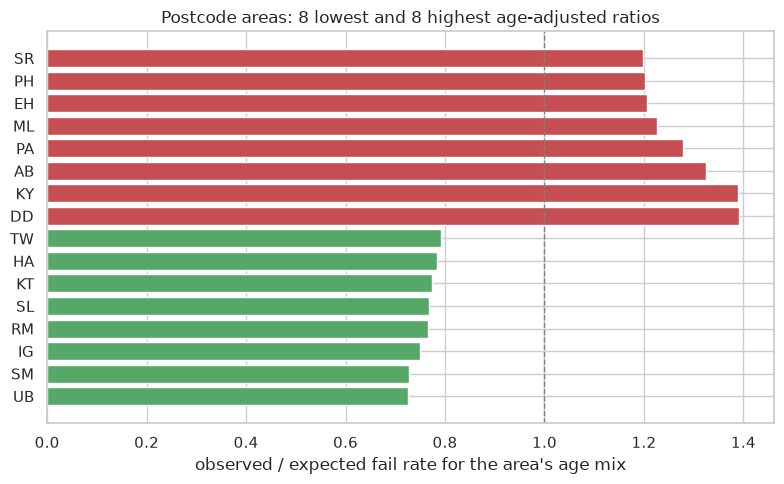

,tests,median_age,fail_rate,age_adjusted_ratio
postcode_area,,,,
UB,5865,9.958,0.208,0.725
SM,2289,10.023,0.211,0.727
IG,4276,8.964,0.200,0.750
RM,7897,9.153,0.209,0.766
SL,7240,10.023,0.220,0.767
KT,8555,9.347,0.214,0.774
HA,5771,9.500,0.220,0.785
TW,7346,9.209,0.218,0.791
DD,4083,8.454,0.353,1.392


In [24]:
areas = age_adjusted(df, "postcode_area")
print(f"{len(areas)} areas with ≥{MIN_N} tests; raw fail rate range "
      f"{areas['fail_rate'].min():.3f}–{areas['fail_rate'].max():.3f}; "
      f"age-adjusted ratio range {areas['age_adjusted_ratio'].min():.2f}–{areas['age_adjusted_ratio'].max():.2f}")
ext = pd.concat([areas.nsmallest(8, "age_adjusted_ratio"), areas.nlargest(8, "age_adjusted_ratio")])
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(ext.index.astype(str), ext["age_adjusted_ratio"],
        color=["#55a868"] * 8 + ["#c44e52"] * 8)
ax.axvline(1, ls="--", c="grey", lw=1)
ax.set(xlabel="observed / expected fail rate for the area's age mix",
       title="Postcode areas: 8 lowest and 8 highest age-adjusted ratios")
plt.tight_layout(); plt.show()
ext[["tests", "median_age", "fail_rate", "age_adjusted_ratio"]]

**A clear geographic pattern.**
- Across the 116 areas with at least 500 tests, raw fail rates range from 20.0% to 36.9%, and age-adjusted ratios from 0.72 to 1.39.
- **Lowest:** outer London (UB, SM, IG, RM, KT, HA, TW) and Slough (SL), about 21–28% below expectation.
- **Highest:** mostly Scotland (DD Dundee, KY Kirkcaldy, AB Aberdeen, PA Paisley, ML Motherwell, EH Edinburgh, PH Perth), plus Sunderland (SR), 20–39% above expectation, even though their fleets are *younger*.

Possible explanations, **none tested here**: climate and road salt (corrosion), mileage per year (not adjusted), or differences in testing practice between stations.

**For Section E.** Region is predictive, but if part of the effect is *testing practice* rather than car condition, the model would pass that on to buyers in those areas. The fairness check therefore compares the model's errors across regions.

### B.12 The previous test

**Purpose:** the history features are the main thing our model adds beyond the vehicle record. How much does last year's result tell us about this year's?

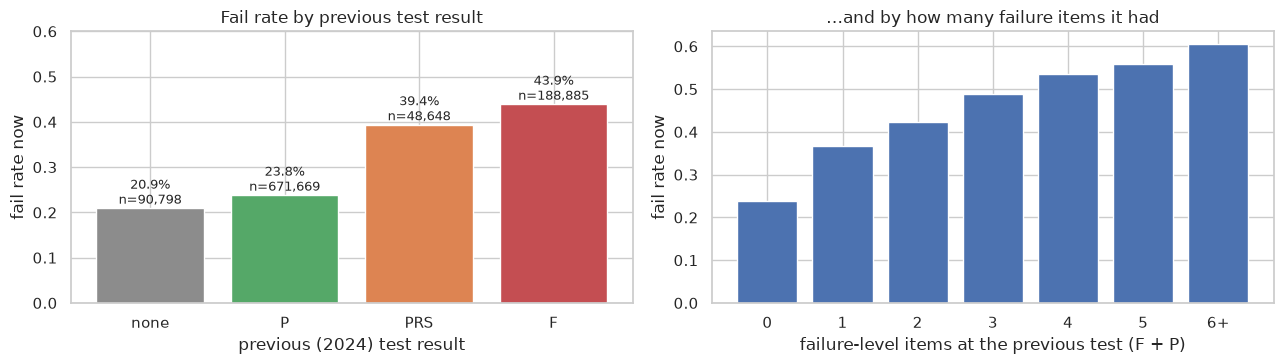

                      tests  fail_rate
prev_result_or_none                   
none                  90798      0.209
P                    671669      0.238
PRS                   48648      0.394
F                    188885      0.439
                  tests  fail_rate
prev_fail_items                   
0                671819      0.238
1                104976      0.368
2                 62347      0.423
3                 31391      0.489
4                 17594      0.535
5                  9386      0.560
6                 11689      0.605


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
order = ["none", "P", "PRS", "F"]
r = df.groupby("prev_result_or_none")["fail"].agg(tests="size", fail_rate="mean").reindex(order)
axes[0].bar(r.index, r["fail_rate"], color=["#8c8c8c", "#55a868", "#dd8452", "#c44e52"])
for i, (n, v) in enumerate(zip(r["tests"], r["fail_rate"])):
    axes[0].text(i, v + 0.01, f"{v:.1%}\nn={n:,}", ha="center", fontsize=9)
axes[0].set(xlabel="previous (2024) test result", ylabel="fail rate now", ylim=(0, 0.6),
            title="Fail rate by previous test result")

prev = df[df["has_prev_test"] == 1].copy()
prev["prev_fail_items"] = (prev["prev_items_F"] + prev["prev_items_P"]).clip(upper=6).astype(int)
k = prev.groupby("prev_fail_items")["fail"].agg(tests="size", fail_rate="mean")
axes[1].bar(k.index.astype(str).str.replace("6", "6+"), k["fail_rate"], color="#4c72b0")
axes[1].set(xlabel="failure-level items at the previous test (F + P)", ylabel="fail rate now",
            title="…and by how many failure items it had")
plt.tight_layout(); plt.show()
print(r.to_string()); print(k.to_string())

**Last year predicts this year, with a dose-response.**
- After a **pass**, 23.8% fail now. After a **PRS**, 39.4%. After a **fail**, 43.9%.
- The fail rate rises steadily with the **number** of failure-level items at the previous test: 23.8% (none), 36.8% (1), 42.3% (2) … 60.5% (6 or more).
- Cars with **no previous test** fail least (20.9%), because most of them are on their first MOT.

The history features (`prev_fail`, item counts) should be among the model's most useful inputs. A buyer can see the same information on the public MOT history service, so this is not leakage: it is known before the test.

### B.13 What failed at the previous test (join 4: defects ⨝ DVSA defect lookups)

**Purpose:** the history features count failure items, but *which* parts fail? This shows what the model's history signal is made of, and what a buyer should check.

The table built from the 2024 test-item extracts (`data/processed/mot_2024_prev_failure_reasons.csv`) holds failure-level items only: **F** (failed) and **P** (repaired at the station). It is joined to DVSA's defect definitions (`rfr_id`, one-to-one) and then to the test-item hierarchy twice, once for the item name and once for its section (many-to-one).

In [26]:
from motfail.load import load_item_detail, load_item_group, load_prev_failure_reasons

reasons = load_prev_failure_reasons()
detail = load_item_detail()[["rfr_id", "rfr_desc", "rfr_deficiency_category", "test_item_id", "test_item_set_section_id"]]
groups = load_item_group()[["test_item_id", "item_name"]]
assert reasons["rfr_id"].is_unique and detail["rfr_id"].is_unique and groups["test_item_id"].is_unique

r = reasons.merge(detail, on="rfr_id", how="left", validate="one_to_one", indicator=True)
print(f"reasons {len(reasons):,} | matched to a defect definition {(r['_merge'] == 'both').sum():,} | "
      f"unmatched {(r['_merge'] == 'left_only').sum():,} "
      f"({r.loc[r['_merge'] == 'left_only', 'n_items'].sum() / r['n_items'].sum():.2%} of items)")
r = r.drop(columns="_merge")
r = r.merge(groups.rename(columns={"item_name": "item"}), on="test_item_id", how="left", validate="many_to_one")
r = r.merge(groups.rename(columns={"test_item_id": "test_item_set_section_id", "item_name": "section"}),
            on="test_item_set_section_id", how="left", validate="many_to_one")
assert len(r) == len(reasons)

n_prev_failed = int(((df["prev_items_F"] + df["prev_items_P"]) > 0).sum())
print(f"previous tests with at least one failure-level item: {n_prev_failed:,}")

reasons 1,181 | matched to a defect definition 1,180 | unmatched 1 (0.00% of items)
previous tests with at least one failure-level item: 237,383


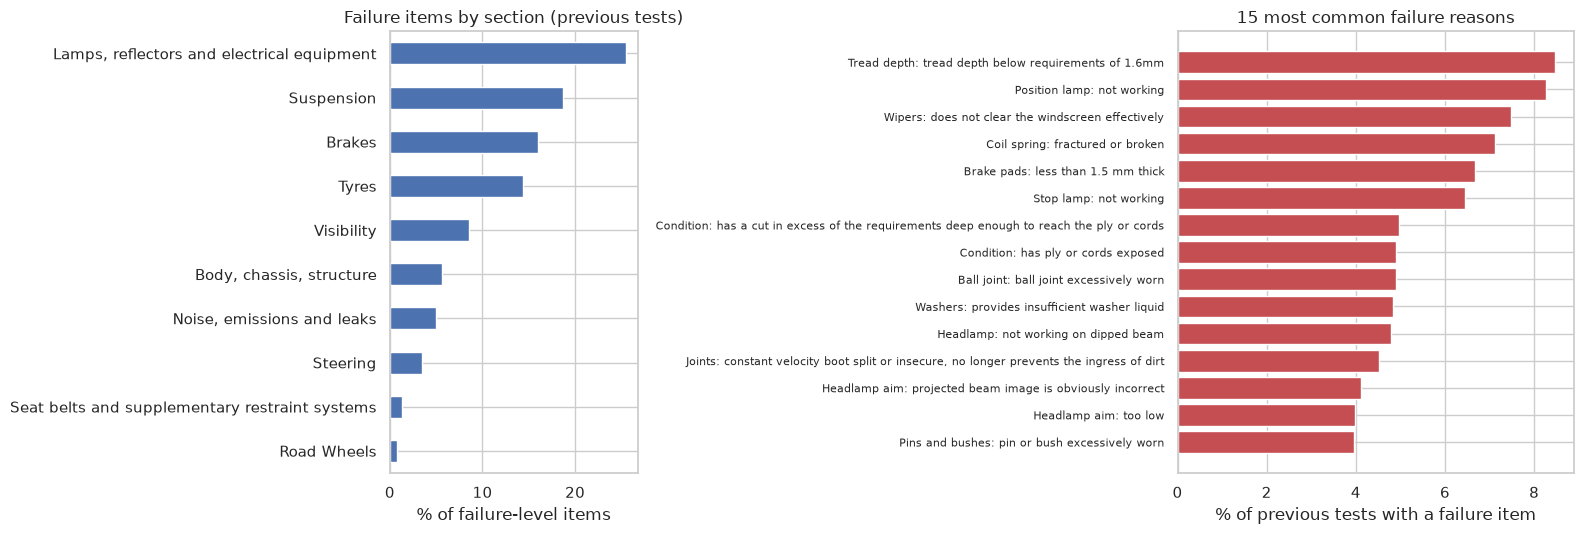

section
Lamps, reflectors and electrical equipment       25.500
Suspension                                       18.700
Brakes                                           16.000
Tyres                                            14.300
Visibility                                        8.600
Body, chassis, structure                          5.700
Noise, emissions and leaks                        5.000
Steering                                          3.400
Seat belts and supplementary restraint systems    1.400
Road Wheels                                       0.700


,reason,section,rfr_deficiency_category,n_tests,share_of_failed_tests
0,Tread depth: tread depth below requirements of...,Tyres,Dangerous,20108,8.500
1,Position lamp: not working,"Lamps, reflectors and electrical equipment",Major,19599,8.300
2,Wipers: does not clear the windscreen effectively,Visibility,Major,17764,7.500
3,Coil spring: fractured or broken,Suspension,Major,16889,7.100
4,Brake pads: less than 1.5 mm thick,Brakes,Dangerous,15859,6.700
5,Stop lamp: not working,"Lamps, reflectors and electrical equipment",Major,15334,6.500
6,Condition: has a cut in excess of the requirem...,Tyres,Major,11770,5.000
7,Condition: has ply or cords exposed,Tyres,Dangerous,11642,4.900
8,Ball joint: ball joint excessively worn,Suspension,Major,11619,4.900
9,Washers: provides insufficient washer liquid,Visibility,Major,11471,4.800


In [27]:
sec = (r.groupby("section")["n_items"].sum().sort_values(ascending=False) / r["n_items"].sum() * 100)
top = r.nlargest(15, "n_tests").assign(
    reason=lambda t: t["item"].str.strip() + ": " + t["rfr_desc"].str.strip(),
    share_of_failed_tests=lambda t: t["n_tests"] / n_prev_failed * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
sec.head(10).iloc[::-1].plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set(xlabel="% of failure-level items", ylabel="", title="Failure items by section (previous tests)")
axes[1].barh(top["reason"].iloc[::-1], top["share_of_failed_tests"].iloc[::-1], color="#c44e52")
axes[1].set(xlabel="% of previous tests with a failure item", title="15 most common failure reasons")
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
print(sec.head(10).round(1).to_string())
top[["reason", "section", "rfr_deficiency_category", "n_tests", "share_of_failed_tests"]].round(1)

**Join 4 result.** 1,180 of the 1,181 failure reasons match a DVSA defect definition. The one unmatched code covers under 0.01% of items. Every key was unique (asserted), and the row count is unchanged after both item-group joins.

**What fails.**
- **Four sections make up 74.5% of failure-level items:**

  | section | share of failure items |
  |---|---|
  | lamps, reflectors and electrics | 25.5% |
  | suspension | 18.7% |
  | brakes | 16.0% |
  | tyres | 14.3% |

- **The single most common reasons** are cheap, owner-checkable items:

  | reason | share of failed tests |
  |---|---|
  | tyre tread below 1.6 mm | 8.5% |
  | a position lamp not working | 8.3% |
  | wipers not clearing the screen | 7.5% |
  | a broken coil spring | 7.1% |
  | brake pads under 1.5 mm | 6.7% |
  | a stop lamp not working | 6.5% |

**Two consequences:**
1. **Buyer advice.** Many fails are avoidable with a five-minute check (bulbs, wipers, washer fluid, tyre tread). The app can say so next to a high predicted risk.
2. **A limit on accuracy.** Whether a bulb has blown or a tyre is just under the limit *on the test day* is close to random. No pre-test feature can predict that, so even a perfect model will have a noisy ceiling. This is reported as a limitation, not hidden.
- Wear parts (springs, ball joints, bushes, brake pads) are what age and mileage stand for in B.9: they wear out with use.

### B.14 EDA summary: five key facts

1. **The target is imbalanced: 28.1% fail.**
   - Always predicting *pass* gives 71.9% accuracy, so we use precision, recall, F2 and PR-AUC instead.
   - Splits are stratified.
2. **Age and mileage are the strongest numeric signals** (Spearman 0.23 each with `fail`).
   - Each still matters with the other held within a band.
   - Both effects are **non-linear**: mileage plateaus after about 100k miles, and age falls after about 20 years (survivor effect). Tree models suit this; the linear model needs bins or transforms.
3. **Last year's test predicts this year's** with a dose-response: 23.8% after a pass, 43.9% after a fail, 60.5% after 6 or more failure items.
4. **Brand and region effects are real but confounded by fleet age.**
   - After age adjustment, makes range from 0.76 (BMW) to 1.34 (Renault).
   - Postcode areas range from 0.72 (outer London) to 1.39 (Dundee).
   - So the model needs these features *together* with age, and the regional pattern is checked for fairness in Section E.
5. **Data quality needs care before modelling:**
   - three missing-value mechanisms (no previous test; EVs have no engine size; fuels written as words)
   - informative "errors" (cars with mileage recorded as 0 fail 48.8%)
   - impossible values (55,000 cc engines, 999,999 miles, mileage jumps of ±900k)

   Section C handles each one explicitly.

No single feature is strong (the largest |correlation| is about 0.23), and many failures are cheap random wear items (B.13). So a multivariable model is needed, and its accuracy will have a natural ceiling.

## C. Data preparation

Preparation has two kinds of step, kept apart on purpose:

| kind | where | when | examples |
|---|---|---|---|
| row-level fixes with **fixed limits** from domain knowledge | `src/motfail/clean.py` | before the split, on all rows | impossible values → missing, placeholders → missing, retests dropped |
| steps that **learn from the data** | the scikit-learn `Pipeline` (C.6) | fitted on training rows only | imputation values, scaling, encoding |

A fixed limit such as "no car engine is over 10,000 cc" uses nothing from other rows, so applying it before the split cannot leak information from the test set. A median does use other rows, so imputation waits for the pipeline.

**An honest caveat.** The EDA (section B) and the choice of these limits looked at all 1,000,000 rows, including those that later become the test set. The limits are set from domain knowledge, such as engine sizes that exist, not tuned to the target. And everything that *learns* (C.6, C.7, section D) uses training rows only. So the effect on the test estimate is negligible, but it is stated rather than hidden.

### C.1 Correcting error data

In [28]:
from motfail.clean import CC_MAX, CC_MIN, MILEAGE_MAX, NOT_FEATURES, RETEST_DAYS, check_no_leakage, clean

raw = sample.merge(history, on="test_id", how="left", validate="one_to_one")  # the A.3 join, without the EDA columns
raw["fail"] = make_label(raw)
clean_df, cleaning_report = clean(raw)
print(f"{len(raw):,} rows → {len(clean_df):,} after cleaning")
cleaning_report

1,000,000 rows → 999,626 after cleaning


,step,column,action,rows,share_%
0,duplicate test,test_id,drop row,0,0.000
1,test < 30 days after the previous one (a retes...,days_since_prev,drop row,374,0.037
2,date stored as text,"test_date, first_use_date",convert to date; unparseable → missing,0,0.000
3,fuel name instead of code,fuel_type,recode to the lookup's code,11818,1.182
4,"placeholder 'UNCLASSIFIED', 'UNKNOWN UNKNOWN'",make,set missing,4,0.000
5,"placeholder 'UNCLASSIFIED', '-', '.'",model,set missing,2073,0.207
6,placeholder 'NOT STATED',colour,set missing,7,0.001
7,"invalid reading at either test, or change > 10...","miles_since_prev, mileage_rollback",set missing,2473,0.247
8,mileage 0,test_mileage,set missing,1785,0.178
9,"mileage > 500,000",test_mileage,set missing,79,0.008


In [29]:
# Evidence 1: fail rate of the groups the rules touch
groups = {
    "all tests": raw["fail"],
    f"< {RETEST_DAYS} days after the previous test": raw.loc[raw["days_since_prev"] < RETEST_DAYS, "fail"],
    "mileage 0": raw.loc[raw["test_mileage"] == 0, "fail"],
    f"mileage > {MILEAGE_MAX:,}": raw.loc[raw["test_mileage"] > MILEAGE_MAX, "fail"],
    "model UNCLASSIFIED": raw.loc[raw["model"] == "UNCLASSIFIED", "fail"],
}
evidence = pd.DataFrame({k: {"tests": len(v), "fail rate %": 100 * v.mean()} for k, v in groups.items()}).T
evidence.astype({"tests": int}).round(1)

,tests,fail rate %
all tests,1000000,28.100
< 30 days after the previous test,374,17.600
mileage 0,1786,48.800
"mileage > 500,000",79,38.000
model UNCLASSIFIED,2065,20.300


In [30]:
# Evidence 2: fixed limits against the IQR rule (seminar deck p.10)
def iqr_fences(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

rows = []
for col, (lo_fixed, hi_fixed) in {"test_mileage": (1, MILEAGE_MAX), "cylinder_capacity": (CC_MIN, CC_MAX)}.items():
    s = raw[col].dropna()
    lo, hi = iqr_fences(s)
    rows.append({
        "column": col,
        "IQR fences": f"{lo:,.0f} to {hi:,.0f}",
        "outside IQR fences": int(((s < lo) | (s > hi)).sum()),
        "fixed limits": f"{lo_fixed:,} to {hi_fixed:,}",
        "outside fixed limits": int(((s < lo_fixed) | (s > hi_fixed)).sum()),
    })
print("mileage quantiles:", raw["test_mileage"].quantile([0.99, 0.999, 0.9999]).round(0).to_dict())
pd.DataFrame(rows)

mileage quantiles: {0.99: 212264.0, 0.999: 308711.0, 0.9999: 460565.0}


,column,IQR fences,outside IQR fences,fixed limits,outside fixed limits
0,test_mileage,"-48,050 to 189,714",19686,"1 to 500,000",1865
1,cylinder_capacity,"336 to 2,984",44369,"50 to 10,000",63


In [31]:
# Evidence 3: every engine size over 8,000 cc, and what the 10,000 cc limit does with it
big = raw.loc[raw["cylinder_capacity"] > 8_000, ["make", "model", "fuel_type", "cylinder_capacity"]]
big = big.sort_values("cylinder_capacity").assign(rule=lambda d: np.where(d["cylinder_capacity"] > CC_MAX, "set missing", "kept"))
print(big.to_string(index=False))
print("values under", CC_MIN, "cc:", raw.loc[raw["cylinder_capacity"] < CC_MIN, "cylinder_capacity"].value_counts().sort_index().to_dict())

           make             model               fuel_type  cylinder_capacity        rule
      WINNEBAGO         WORKHORSE                      LP          8,100.000        kept
         SAFARI     MOTOR CARAVAN                      PE          8,100.000        kept
          DAMON          DAYBREAK                      PE          8,100.000        kept
    GEORGIE BOY            LANDAU                      PE          8,160.000        kept
          DODGE            SRT-10                      PE          8,277.000        kept
          DODGE               RAM                      DI          8,277.000        kept
          DODGE               RAM                      PE          8,277.000        kept
     AM GENERAL            M925A2                      DI          8,300.000        kept
    DODGE (USA)            SRT 10                      PE          8,300.000        kept
         MONACO           CAMELOT                      DI          8,300.000        kept
         MONACO     M

**Decisions** (each count is from the report above):

| issue | choice | alternative rejected | why | evidence |
|---|---|---|---|---|
| test < 30 days after the previous one (374) | drop the row | keep it and let `days_since_prev` explain it | These are retests across New Year: 93% followed a fail, and only 17.6% fail again (the car was repaired). Same-year repeats were already removed for this reason (D6, `data/SOURCE.md`), so one rule now covers the whole population. | evidence 1 |
| fuel written as a name (11,818) | recode to the DVSA code | keep both spellings | `ELECTRIC` and `EL` are the same fuel. Two spellings would split one group in two. | A.4 |
| placeholders: `UNCLASSIFIED`, `UNKNOWN UNKNOWN`, `-`, `.`, `NOT STATED` | set missing | keep as a level | `UNCLASSIFIED` is not a model. As one level it would lump 2,065 unrelated cars of many makes together. They fail less (20.3%), so the missing flag keeps that signal (C.2). | evidence 1 |
| mileage 0 (1,785) | set missing; the pipeline adds a missing flag | drop the rows, or impute without a flag | 0 is not a true reading for cars mostly 10+ years old (B.3). They fail 48.8%: dropping them loses an informative group, and a plain median would hide it. | evidence 1 |
| mileage over 500,000 (79) | set missing | cap at 500,000 (winsorise) | Values such as 999,999 and 600,000 (three times) are placeholders or typing slips, not long journeys. Capping would keep a false number. 500,000 is above the 99.99th percentile (460,565). | evidence 2 |
| miles since the previous test (2,473) | set missing if either reading is invalid or the change is over 100,000 | keep | A difference computed from a wrong reading is also wrong. The previous reading was 0 for 1,348 cars. Rollbacks under 100,000 miles are kept: they can be real clocking. | `data/SOURCE.md` |
| engine under 50 cc (50) | set missing | none | 0 to 30 cc is not a car engine; most likely a typing slip. | evidence 3 |
| engine over 10,000 cc (13) | set missing | the 8,000 cc limit first planned | From 8,100 to 9,603 cc the vehicles are plausibly real: Dodge SRT-10 and Ram, US motorhomes (Winnebago, Monaco, Fleetwood). Above 10,000 cc are ordinary cars with impossible values (Mondeo 11,560; Prius 17,980; Range Rover Sport 49,999), plus four truck-based vehicles (DAF, Scania, Newell, a Mercedes-Benz motorhome) that may be real and lose their engine size. | evidence 3 |
| first use after the test date (1) | set missing | drop the row | Only the age is unknown; the rest of the row is usable. | |
| first use exactly 1971-01-01 (6) | set missing | keep | The DVSA user guide (v5.1) says DVLA gives this date to vehicles with an unknown date of manufacture, so these ages (about 54 years) are false. 6 cars on one day, against about 0.2 a day for the rest of 1971. | user guide |
| cars under 3 years old (45,665; 2,453 under 2.5 years) | **kept** | drop as impossible (the first MOT is due at 3 years) | Not impossible: GOV.UK says some vehicles need their first MOT at 1 year. They fail far less (11.3% under 3 years; 6.6% under 2.5), consistent with real tests of new cars. | C.2 (coverage check) |
| postcode area `XX` (63) | **kept as a level** | set missing (our first version) | Not a placeholder: the user guide says `XX` merges regions with fewer than 5 test stations, to protect station anonymity. It is a real, if mixed, area. | user guide |

**Why fixed limits and not the IQR rule.**
- The IQR rule (seminar deck p.10) would flag **19,686 mileages and 44,369 engine sizes**. These are real high-mileage cars and big engines, the "rare real events" the deck warns against removing.
- The fixed limits flag **1,865 and 63**. Every engine size they flag is listed above; the flagged mileages are zeros or above the 99.99th percentile.
- Real extremes stay in the data.

**What fixed limits miss.**
- Errors inside the range survive: a Mazda MX-5 at 9,999 cc is kept.
- A per-model check (say, over 3 times the model's median engine size) would catch it. But that learns from the data, so it would have to be fitted on training rows only.
- For fewer than 100 rows in a million, it is not worth it.

### C.2 Missing values after cleaning

In [32]:
miss = clean_df.isna()
missing = pd.DataFrame({
    "missing": miss.sum(),
    "missing %": 100 * miss.mean(),
    "fail % if missing": [100 * clean_df.loc[miss[c], "fail"].mean() if miss[c].any() else np.nan for c in miss.columns],
    "fail % if present": [100 * clean_df.loc[~miss[c], "fail"].mean() for c in miss.columns],
})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
no_engine = clean_df["cylinder_capacity"].isna()
print(f"engine size missing: {no_engine.sum():,}, of which electric: {(no_engine & clean_df['fuel_type'].eq('EL')).sum():,}")
missing.round(1)

engine size missing: 20,784, of which electric: 20,463


,missing,missing %,fail % if missing,fail % if present
mileage_rollback,93271,9.300,21.600,28.800
miles_since_prev,93271,9.300,21.600,28.800
prev_result,90798,9.100,20.900,28.800
prev_fail,90798,9.100,20.900,28.800
prev_items_A,90798,9.100,20.900,28.800
days_since_prev,90798,9.100,20.900,28.800
prev_items_M,90798,9.100,20.900,28.800
prev_items_F,90798,9.100,20.900,28.800
prev_items_P,90798,9.100,20.900,28.800
prev_dangerous,90798,9.100,20.900,28.800


**Mechanism → treatment.** Every treatment that learns a value is fitted inside the pipeline (C.6), on training rows only.

| column | missing | mechanism | fail % missing vs present | treatment |
|---|---|---|---|---|
| previous-test features (`prev_*`, `days_since_prev`) | 90,798 (9.1%) | **structural**: no 2024 test. Mostly first MOTs at 3 years, or a last test before 2024 (A.3). | 20.9 vs 28.8 | `has_prev_test` already flags it; item counts → 0; result → its own "none" level |
| `miles_since_prev`, `mileage_rollback` | 2,473 more | the above, plus an invalid reading (C.1) | 21.6 vs 28.8 | median + missing flag |
| `cylinder_capacity` | 20,784 (2.1%) | **structural for 20,463 electric cars** (no engine); 321 others not recorded | 15.4 vs 28.4 | median + missing flag (the flag is almost an "electric" flag; fuel type is also a feature) |
| `test_mileage` | 1,864 (0.2%) | **informative, not at random**: zero or impossible readings | 48.3 vs 28.1 | median + missing flag (the flag carries the signal) |
| `model` | 2,074 (0.2%) | DVSA could not classify it; informative | 20.3 vs 28.1 | its own "missing" level in the encoder |
| `make`, `colour`, `first_use_date` | 4 to 7 | too few to matter; treated as random | n/a | most frequent value / median |

**Why the median.** Mileage and engine size are right-skewed (B.2), and the median resists outliers (seminar deck p.5).

**Why not drop rows with gaps.** The missing rows are not a random subset: their fail rates differ from the rest by up to 20 points. Dropping them would bias the data and remove first-MOT cars entirely, yet the model must predict for them. The missing flags (`SimpleImputer(add_indicator=True)`) let the model use the fact that a value is missing.

In [33]:
# Limitation check: is "no previous test" the same thing in every month?
by_month = clean_df.groupby(clean_df["test_date"].dt.month).agg(
    has_previous_test=("has_prev_test", "mean"), tests=("test_id", "size"))
by_month["has_previous_test"] = (100 * by_month["has_previous_test"]).round(1)
by_month.T

test_date,1,2,3,4,5,6,7,8,9,10,11,12
has_previous_test,82.500,89.100,90.100,89.700,90.800,91.900,92.900,93.300,92.700,93.500,93.300,92.300
tests,"92,306.000","84,861.000","101,471.000","74,908.000","75,489.000","80,697.000","84,066.000","78,212.000","96,967.000","94,938.000","79,262.000","56,449.000"


**A limitation of the history features.** The share of tests with a previous test found rises from **82.5% in January to about 93% from July on**.
- **The cause is the data window, not the cars.** Only 2024 tests are searched, so a January 2025 test can look back about 12 months and a December test about 23.
- A car tested in January 2025 whose last MOT was in December 2023 counts as "no previous test", although it had one.
- So `has_prev_test` partly reflects the **test month**, and a real buyer, who sees the full MOT history, would get a slightly different input.
- **Fix:** add the 2023 extracts and use the same 2-year look-back for every test. This is planned for week 3 (D11). Until then it is a documented limitation, and the month features let the model absorb part of it.

### C.3 Leakage guard

In [34]:
assert "completed_date" not in clean_df.columns                     # recorded when the test ends: dropped at sampling (D6)
assert clean_df["vehicle_id"].is_unique                             # one test per car
assert (clean_df["days_since_prev"].dropna() >= RETEST_DAYS).all()  # previous test strictly earlier, and not a retest
try:
    check_no_leakage(["test_mileage", "test_result"])
except ValueError as err:
    print("guard works:", err)
pd.Series(NOT_FEATURES, name="why it is not a feature").rename_axis("column").to_frame()

guard works: not allowed as features: ['test_result']


,why it is not a feature
column,
test_id,identifier
vehicle_id,identifier (used only to check that no car is ...
test_result,the target's source
fail,the target
completed_date,recorded when the test ends (leakage)
test_class_id,constant after filtering (cars only)
test_type,constant after filtering (initial tests only)
test_date,raw date; used only through derived features (...
first_use_date,raw date; used only through derived features (...


**Three ways information could leak, and the guard for each.**
1. **Columns recorded at or after the test** (`completed_date`, the result itself):
   - `completed_date` was dropped when the sample was made.
   - `check_no_leakage` rejects every column above from any feature list. It is tested for each column in `tests/test_clean.py`, and C.4 passes the feature list through it.
2. **History from the future.** The previous test must be strictly before the 2025 test (`tests/test_history.py`), and, after C.1, at least 30 days before.
3. **The same car on both sides of the split.** Each car appears once (asserted above; D6). So a plain stratified split cannot put one car in both train and test, and the split in C.5 asserts it again.

### C.4 Feature engineering

Every feature is something a buyer or owner knows **before** the test: the car's details, the booking (date, station area) and the car's public MOT history. Each one is computed from its own row with a fixed formula (`src/motfail/features.py`), so it is safe before the split.

| feature | formula | why (domain) |
|---|---|---|
| `vehicle_age` | (test date − first use date) / 365.25 | wear and corrosion build up with age (B.9) |
| `miles_per_year` | mileage / max(age, 1 year) | usage intensity: two cars of the same age can have very different wear |
| `test_month` | month of the test date | seasonality (B.6): winter roads, lighting |
| `fuel_group` | DVSA fuel code → petrol, diesel, hybrid, electric, other | 12 codes, 7 of them with under 300 cars, are pooled into "other" (589 cars) |
| `make_model` | make + " \| " + model | model names repeat across makes (checked below), so the model alone is not a key |
| previous-test features | from the 2024 test (A.2) | last year's result predicts this year's, with a dose-response (B.12) |

The feature list is passed through the leakage guard (C.3).

In [35]:
from motfail.features import FEATURES, HIGH_CARD, LOW_CARD, add_features, feature_frame

data = add_features(clean_df)
check_no_leakage(FEATURES)  # raises if any id, target or end-of-test column were a feature

shared = data.groupby("model", observed=True)["make"].nunique()
shared = shared[shared > 1]
print(f"{len(FEATURES)} features | model names used by more than one make: {len(shared):,} "
      f"({data['model'].isin(shared.index).mean():.1%} of tests), e.g. COUPE under {shared['COUPE']} makes")
data[["vehicle_age", "miles_per_year"]].describe().T

20 features | model names used by more than one make: 262 (17.4% of tests), e.g. COUPE under 12 makes


,count,mean,std,min,25%,50%,75%,max
vehicle_age,"999,619.000",10.700,5.619,0.000,6.746,9.930,13.900,120.665
miles_per_year,"997,755.000","7,628.886","4,201.822",0.018,"4,916.851","6,985.083","9,437.002","158,480.000"


- **The make + model key is needed.** 262 model names belong to more than one make (17.4% of tests); `COUPE` alone is used by 12 makes. Keyed on the model name alone, these unrelated cars would share one fail rate.
- **Extreme values that remain are kept on purpose:**
  - `vehicle_age` reaches 120 years. 1,495 cars are over 40: real historic vehicles, which are exempt from the MOT but can still be tested. They fail 17.3%.
  - `miles_per_year` has 158 cars above 50,000 a year. These are young cars (median 3 years) with high readings, such as private-hire use, so they are real enough. The 99.9th percentile is 36,402.
  - Trees are unaffected by extremes. For logistic regression, scaling keeps them from dominating, and section D checks whether a log transform helps.

### C.5 Train / validation / test split

- **70 / 15 / 15, stratified by `fail`, seed 42.**
  - **train:** fitting, and 5-fold cross-validation for tuning (section D)
  - **validation:** the decision threshold and comparing tuned models
  - **test:** used **once**, for the final comparison (section E)
- The split happens **before any learned step**, so nothing learned from validation or test rows can reach training.
- Stratifying keeps the 28.1% fail rate the same in all three parts.
- A split grouped by vehicle is not needed: each car appears once (D6). `split()` still raises an error if a vehicle ever lands in two parts.

In [36]:
from motfail.pipeline import SEED as SPLIT_SEED, make_preprocessor, split

train_df, val_df, test_df = split(data, seed=SPLIT_SEED)
pd.DataFrame({
    "rows": [len(p) for p in (train_df, val_df, test_df)],
    "share %": [100 * len(p) / len(data) for p in (train_df, val_df, test_df)],
    "fail rate %": [100 * p["fail"].mean() for p in (train_df, val_df, test_df)],
}, index=["train", "validation", "test"]).round(2)

,rows,share %,fail rate %
train,699738,70.000,28.100
validation,149944,15.000,28.100
test,149944,15.000,28.100


The three parts have exactly the planned sizes, and the fail rate is 28.1% in each, as stratification intends.

### C.6 The preprocessing pipeline

Every step below learns something from data, so it sits in a scikit-learn `ColumnTransformer`. That transformer goes **inside** a `Pipeline` with each model. As a result, `fit` uses training rows only, and cross-validation refits it inside every fold.

| columns | step | why | alternative rejected |
|---|---|---|---|
| mileage, engine size, miles since previous test | median + **missing flag** | right-skewed (B.2): the median resists outliers (seminar deck p.5); missingness is informative (C.2) | mean (pulled by the skew); dropping rows (biased, C.2) |
| other numeric (age, miles per year, gap since previous test, item counts) | median | almost never missing (only when there is no previous test, which `has_prev_test` already flags) | none |
| all numeric outputs | **z-score scaling** (`StandardScaler`) | logistic regression and KNN are scale-sensitive (lecture 3 slide 13); trees are unaffected | min-max: one extreme value squeezes the rest (deck p.6) |
| fuel group, colour, previous result, month | **one-hot**; missing is its own level; an unseen level → all zeros | nominal, with few levels | ordinal codes: they invent an order |
| make, make + model, postcode area | **target encoding**: the fail rate of the level, shrunk towards the overall rate when the level is rare, then scaled | 779 / 9,411 / 119 levels: one-hot would add about 10,000 columns, and 7,234 make-model pairs have under 20 tests | one-hot with rare levels pooled (compared in C.7) |

**How target encoding avoids leakage.** Lecture 3 slide 15 introduces mean target encoding. Used naively, each row's own label leaks into its encoding. scikit-learn's `TargetEncoder` prevents this in two ways:
- On the training rows it **cross-fits**: each row is encoded with means from the other 4 of 5 folds.
- It shrinks rare levels towards the overall fail rate (empirical-Bayes smoothing). An unseen make or model gets the overall rate.

The diagram below is the fitted pipeline.

In [37]:
X_train, y_train = feature_frame(train_df)
X_val, y_val = feature_frame(val_df)
X_test, y_test = feature_frame(test_df)

preprocessor = make_preprocessor(seed=SPLIT_SEED)
Z_train = preprocessor.fit_transform(X_train, y_train)  # learns medians, scales, target means: training rows only
Z_val = preprocessor.transform(X_val)
print(f"train {Z_train.shape} | validation {Z_val.shape} | missing values after preprocessing: {int(np.isnan(Z_val).sum())}")
preprocessor

train (699738, 60) | validation (149944, 60) | missing values after preprocessing: 0


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_flag', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feat

In [38]:
# What target encoding learned: makes with at least 2,000 training tests, raw vs encoded fail rate
enc = preprocessor.named_transformers_["high"].named_steps["encode"]
make_codes = pd.Series(enc.encodings_[0], index=enc.categories_[0], name="encoded fail rate")
counts = X_train["make"].value_counts()
raw_rate = train_df.groupby("make", observed=True)["fail"].mean()
check = pd.DataFrame({"training tests": counts, "raw fail rate": raw_rate, "encoded fail rate": make_codes}).dropna()
check = check[check["training tests"] >= 2_000].sort_values("encoded fail rate")
print("overall training fail rate:", round(enc.target_mean_, 3))
pd.concat([check.head(4), check.tail(4)]).round(3)

overall training fail rate: 0.281


,training tests,raw fail rate,encoded fail rate
PORSCHE,"4,071.000",0.129,0.129
TESLA,"2,838.000",0.151,0.151
LEXUS,"3,544.000",0.171,0.171
MG,"3,444.000",0.203,0.203
PEUGEOT,"29,516.000",0.335,0.335
VAUXHALL,"59,727.000",0.346,0.346
CITROEN,"20,764.000",0.374,0.374
RENAULT,"20,286.000",0.386,0.386


- **Output:** 60 columns, with no missing values left in the validation set. So the pipeline handles every gap with values learned on the training rows.
- **What target encoding learned for the big makes:** the encoded rate equals the raw rate, because smoothing only pulls *rare* levels towards the overall 28.1%.
- **The ranking:** Porsche, Tesla and Lexus fail least (13–17%); Peugeot, Vauxhall, Citroën and Renault most (34–39%).
- **This is the raw rate, not the age-adjusted one (B.10).** Part of the gap is fleet age, which the model separates by using age as well.

### C.7 Do the engineered features and the encoding help?

- **Setup:** feature sets are added one at a time, and each is scored by 3-fold stratified cross-validation on a 200,000-row subsample of the **training** part. Validation and test stay untouched.
- **Models:** logistic regression (linear) and histogram gradient boosting (trees), using default settings; tuning is section D's job.
- **Score: PR-AUC** (average precision), the primary metric (section D). A model that guesses scores the fail rate of this subsample, 0.283 (0.281 for all rows).

In [39]:
import time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from motfail.features import BINARY, NUMERIC, NUMERIC_WITH_FLAG

sub = train_df.sample(200_000, random_state=SEED)
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
full = dict(numeric_with_flag=NUMERIC_WITH_FLAG, numeric=NUMERIC, binary=BINARY, low_card=LOW_CARD, high_card=HIGH_CARD)
base = dict(numeric_with_flag=["test_mileage", "cylinder_capacity"], numeric=["vehicle_age"], binary=[],
            low_card=["fuel_group", "colour"], high_card=["make", "model", "postcode_area"])
step2 = {**base, "high_card": ["make", "make_model", "postcode_area"]}
step3 = {**step2, "numeric": ["vehicle_age", "miles_per_year"], "low_card": ["fuel_group", "colour", "test_month"]}
runs = [  # (feature set, columns, model, high-cardinality encoding)
    *[(name, cols, m, "target") for name, cols in [
        ("1 car facts (model name alone)", base), ("2 + make|model key", step2),
        ("3 + miles per year, test month", step3), ("4 + previous-test history (all features)", full),
        ("4 without missing flags", {**full, "numeric_with_flag": [], "numeric": NUMERIC_WITH_FLAG + NUMERIC}),
        ("4 without make, model, area", {**full, "high_card": []}),
    ] for m in ("logistic regression", "gradient boosting")],
    ("4 + previous-test history (all features)", full, "logistic regression", "onehot"),
]
models = {"logistic regression": lambda: LogisticRegression(max_iter=2000),
          "gradient boosting": lambda: HistGradientBoostingClassifier(random_state=SEED)}
rows = []
for name, cols, model, encoding in runs:
    columns = [c for key in ("numeric_with_flag", "numeric", "binary", "low_card", "high_card") for c in cols[key]]
    X_sub, y_sub = feature_frame(sub, columns)
    pipe = Pipeline([("pre", make_preprocessor(seed=SEED, high_card_encoder=encoding, **cols)), ("model", models[model]())])
    start = time.time()
    scores = cross_val_score(pipe, X_sub, y_sub, cv=cv3, scoring="average_precision")
    rows.append({"feature set": name, "model": model, "high-card encoding": encoding,
                 "PR-AUC mean": scores.mean(), "PR-AUC sd": scores.std(), "seconds": time.time() - start})
ablation = pd.DataFrame(rows)
ablation.pivot_table(index=["feature set", "high-card encoding"], columns="model", values="PR-AUC mean", sort=False).round(4)

model                                                        logistic regression  \
feature set                              high-card encoding                        
1 car facts (model name alone)           target                            0.430   
2 + make|model key                       target                            0.430   
3 + miles per year, test month           target                            0.431   
4 + previous-test history (all features) target                            0.470   
                                         onehot                            0.472   
4 without missing flags                  target                            0.470   
4 without make, model, area              target                            0.459   

model                                                        gradient boosting  
feature set                              high-card encoding                     
1 car facts (model name alone)           target                          0.452  
2 + make|model key                       target                          0.452  
3 + miles per year, test month           target                          0.452  
4 + previous-test history (all features) target                          0.485  
                                         onehot                            NaN  
4 without missing flags                  target                          0.485  
4 without make, model, area              target                          0.475

In [40]:
print("fold-to-fold sd of PR-AUC: from", round(ablation["PR-AUC sd"].min(), 4), "to", round(ablation["PR-AUC sd"].max(), 4))
ablation.round(4)

fold-to-fold sd of PR-AUC: from 0.0009 to 0.0032


,feature set,model,high-card encoding,PR-AUC mean,PR-AUC sd,seconds
0,1 car facts (model name alone),logistic regression,target,0.430,0.002,4.636
1,1 car facts (model name alone),gradient boosting,target,0.452,0.001,4.275
2,2 + make|model key,logistic regression,target,0.430,0.002,5.821
3,2 + make|model key,gradient boosting,target,0.452,0.002,5.084
4,"3 + miles per year, test month",logistic regression,target,0.431,0.002,6.700
5,"3 + miles per year, test month",gradient boosting,target,0.452,0.001,6.856
6,4 + previous-test history (all features),logistic regression,target,0.470,0.002,11.116
7,4 + previous-test history (all features),gradient boosting,target,0.485,0.002,11.074
8,4 without missing flags,logistic regression,target,0.470,0.002,13.564
9,4 without missing flags,gradient boosting,target,0.485,0.003,9.020


**What helps, and what does not.** A difference smaller than about 0.002 (one fold-to-fold standard deviation) is noise.

| change | logistic regression | gradient boosting | verdict |
|---|---|---|---|
| + previous-test history | **+0.040** | **+0.033** | the engineering that matters: last year's test is the strongest added signal |
| + make, model, area (target-encoded) vs none | +0.012 | +0.010 | real gain |
| make + model key instead of the model name | 0.000 | 0.000 | no measurable gain; **kept for correctness** (the key is unique, the name is not) |
| + miles per year, test month | +0.001 | 0.000 | no measurable gain; **kept for now**: permutation importance in section E makes the final call |
| missing flags vs none | 0.000 | 0.000 | no gain on this data (few rows miss mileage); **kept** because app users may leave mileage blank |
| one-hot (rare levels pooled) vs target encoding | +0.001 | n/a | a tie for logistic regression; target encoding stays because KNN cannot use about 700 one-hot columns |

**Two honest conclusions:**
1. Most of the signal is in **age, mileage, make/model and last year's test**. The extra domain features add little, because the models can already combine age and mileage themselves.
2. Gradient boosting beats logistic regression by about 0.015 to 0.02 at every step. That fits the non-linear patterns found in B.9 (mileage plateaus, the survivor effect after 20 years), and it is the first evidence for the model choice in section D.